# 03 · Modeling: Predicting Delivery Time

**Goal:** train 4 models that predict delivery time (minutes) and compare them.

**Models**
1. Linear Regression (baseline)
2. Ridge Regression
3. Lasso Regression
4. Random Forest

**Metrics:** R², MAE, RMSE

**Input:** `model_data.csv`, the cleaned and weather-joined data produced by notebook 01.

## 1 · Setup

**1.1 Imports.** We load pandas for tables, matplotlib/seaborn for charts, and scikit-learn for the models and metrics.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

sns.set_theme(style='whitegrid')
FIG = '../reports/figures/'

**1.2 Load data.** Load the cleaned data and check its size. We expect 12,645 rows.

In [2]:
df = pd.read_csv('../data/processed/model_data.csv')
df.shape

(12645, 37)

## 2 · Choose features

**2.1 Define the target and feature lists.** The target is what we predict (delivery time).
Features are the inputs. Based on the EDA, we pick the columns that showed an effect and split them
into 3 groups by how each must be converted to numbers:

- **numeric**: already numbers, only need scaling
- **ordered category**: traffic, which has a natural order (Low < Medium < High < Jam)
- **unordered category**: labels with no order (weather, festival, city type, vehicle, order type)

**Left out on purpose:**
- `ID`, `Delivery_person_ID`: identifiers that carry no general pattern
- `Order_Date`, `Time_Orderd`, `Time_Order_picked`, `order_ts`: already turned into `order_hour`, `is_peak`, `is_weekend`, `is_holiday`
- Latitude/longitude columns: already turned into `distance_km`
- `city_name`: the EDA showed no difference between the 4 cities

In [3]:
target = 'Time_taken(min)'

numeric_cols = ['distance_km', 'Delivery_person_Age', 'Delivery_person_Ratings',
                'multiple_deliveries', 'Vehicle_condition', 'order_hour', 'is_peak',
                'is_weekend', 'is_holiday', 'temp_c', 'rain_mm_day', 'wind_max_kmh']
ordinal_cols = ['Road_traffic_density']
traffic_order = [['Low', 'Medium', 'High', 'Jam']]
nominal_cols = ['Weatherconditions', 'Festival', 'City', 'Type_of_vehicle', 'Type_of_order']

**2.2 Create X and y.** X = the input table (only the chosen features), y = the answer column (delivery time).

In [4]:
X = df[numeric_cols + ordinal_cols + nominal_cols]
y = df[target]
X.shape, y.shape

((12645, 18), (12645,))

## 3 · Train/test split

**3.1 Split 80/20.** We hide 20% of orders from the model. After training, we test on these unseen
orders, like an exam with new questions. `random_state=42` makes the split the same every run.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('X_train:', X_train.shape, ' X_test:', X_test.shape)
print('y_train:', y_train.shape, '   y_test:', y_test.shape)

X_train: (10116, 18)  X_test: (2529, 18)
y_train: (10116,)    y_test: (2529,)


## 4 · Preprocessing

**4.1 Build the preprocessor.** Models only understand numbers, so we convert the columns:

- **Scale** numeric columns so they are on a similar range (Ridge and Lasso need this, because their penalty depends on coefficient size).
- **Ordinal-encode** traffic as 0, 1, 2, 3 because it has a natural order.
- **One-hot encode** the other categories (e.g. Weather becomes `Weather_Fog` = 0/1, `Weather_Sunny` = 0/1 …).
  `handle_unknown='ignore'` stops errors if a rare category (e.g. bicycle) is missing from one split.

> **Note on data leakage:** we put this preprocessor *inside* a Pipeline with each model. That way the
> scaler learns its mean and spread from the **training data only**, and the test set stays truly unseen.
> Scaling the whole dataset before splitting would leak test information into training. (Common viva question.)

In [6]:
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('ord', OrdinalEncoder(categories=traffic_order), ordinal_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), nominal_cols),
])
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ord', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

## 5 · Train the models

**5.0 Helper to score a model.** We score 4 models the same way, so we write one small function that
returns R², MAE and RMSE on the test set.

- **R²**: how much of the variation in delivery time the model explains (1.0 = perfect, 0 = no better than always guessing the average)
- **MAE** (mean absolute error): on average, how many minutes off the prediction is
- **RMSE** (root mean squared error): like MAE, but big mistakes are punished more, because errors are squared before averaging

In [7]:
def score(name, model):
    pred = model.predict(X_test)
    return {'model': name,
            'R2': r2_score(y_test, pred),
            'MAE': mean_absolute_error(y_test, pred),
            'RMSE': root_mean_squared_error(y_test, pred)}

**5.1 Linear Regression (baseline).** It fits a straight-line relationship between each input and delivery time.
It is the simplest model and serves as our baseline: every other model must beat it to be worth using.

In [8]:
lin = Pipeline([('prep', preprocessor), ('model', LinearRegression())])
lin.fit(X_train, y_train)
lin_scores = score('Linear Regression', lin)
lin_scores

{'model': 'Linear Regression',
 'R2': 0.576032943766577,
 'MAE': 4.868812558837213,
 'RMSE': 6.070336691523626}

**5.2 Ridge.** Linear regression with a penalty that keeps coefficients small, which reduces overfitting.
`alpha` controls the penalty strength (bigger = stronger). GridSearchCV tries several alphas
(0.1, 1, 10, 100) with 5-fold cross-validation on the training data and keeps the best one.

In [9]:
ridge = GridSearchCV(Pipeline([('prep', preprocessor), ('model', Ridge())]),
                     {'model__alpha': [0.1, 1, 10, 100]}, cv=5, scoring='r2')
ridge.fit(X_train, y_train)
print('Best alpha:', ridge.best_params_['model__alpha'])
ridge_scores = score('Ridge', ridge)
ridge_scores

Best alpha: 1


{'model': 'Ridge',
 'R2': 0.5760374320167481,
 'MAE': 4.868692747426234,
 'RMSE': 6.0703045601806345}

**5.3 Lasso.** Like Ridge, but its penalty can push the coefficients of useless features to exactly zero,
so it also does feature selection. We try alphas 0.001, 0.01, 0.1, 1. (`max_iter` is raised so the solver has time to converge.)

In [10]:
lasso = GridSearchCV(Pipeline([('prep', preprocessor), ('model', Lasso(max_iter=10000))]),
                     {'model__alpha': [0.001, 0.01, 0.1, 1]}, cv=5, scoring='r2')
lasso.fit(X_train, y_train)
print('Best alpha:', lasso.best_params_['model__alpha'])
lasso_scores = score('Lasso', lasso)
lasso_scores

Best alpha: 0.001


{'model': 'Lasso',
 'R2': 0.57599398541682,
 'MAE': 4.868337196661593,
 'RMSE': 6.070615586857552}

**5.4 Random Forest.** Many decision trees, each trained on a random sample of the data; their predictions
are averaged. Trees can capture step-like effects and interactions (like Fog + Jam) that straight lines can't.

We search a small grid: `n_estimators` (number of trees) in [100, 200] and `max_depth` (how deep each tree may grow)
in [10, 20, None]. `n_jobs=-1` uses all CPU cores.

⏱️ **This cell takes about 1–2 minutes** (6 settings × 5 folds = 30 forests).

In [11]:
rf = GridSearchCV(Pipeline([('prep', preprocessor), ('model', RandomForestRegressor(random_state=42))]),
                  {'model__n_estimators': [100, 200], 'model__max_depth': [10, 20, None]},
                  cv=5, scoring='r2', n_jobs=-1)
rf.fit(X_train, y_train)
print('Best params:', rf.best_params_)
rf_scores = score('Random Forest', rf)
rf_scores

Best params: {'model__max_depth': 10, 'model__n_estimators': 200}


{'model': 'Random Forest',
 'R2': 0.8126669140920204,
 'MAE': 3.247382559818289,
 'RMSE': 4.03509689295686}

## 6 · Compare

**6.1 Results table.** Put all scores in one table, sorted by R² (best first). This table is the main result
of the project, so we also save it to `reports/model_comparison.csv`.

In [12]:
results = pd.DataFrame([lin_scores, ridge_scores, lasso_scores, rf_scores])
results = results.sort_values('R2', ascending=False).round(3).reset_index(drop=True)
results.to_csv('../reports/model_comparison.csv', index=False)
results

,model,R2,MAE,RMSE
0,Random Forest,0.813,3.247,4.035
1,Ridge,0.576,4.869,6.070
2,Linear Regression,0.576,4.869,6.070
3,Lasso,0.576,4.868,6.071


**6.2 Bar chart.** The same comparison as a picture, for the report: R² on the left (higher is better),
MAE in minutes on the right (lower is better).

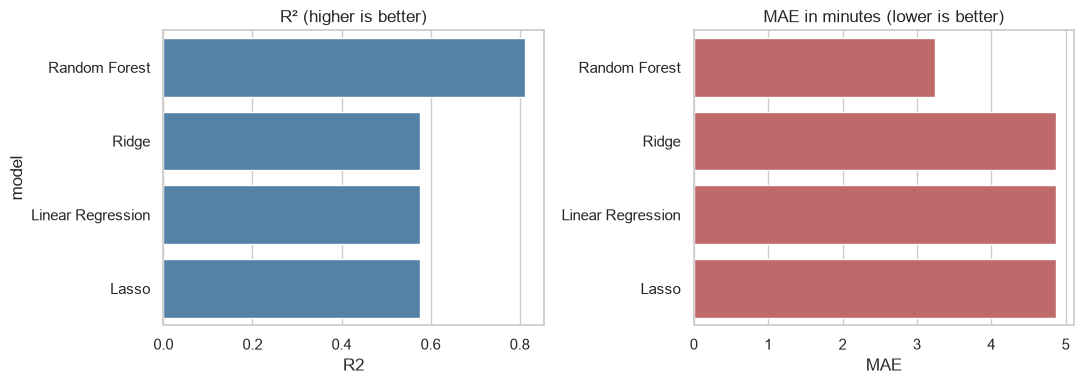

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=results, x='R2', y='model', ax=axes[0], color='steelblue')
sns.barplot(data=results, x='MAE', y='model', ax=axes[1], color='indianred')
axes[0].set_title('R² (higher is better)'); axes[1].set_title('MAE in minutes (lower is better)')
axes[1].set_ylabel('')
plt.tight_layout(); plt.savefig(FIG + '15_model_comparison.png', dpi=120); plt.show()

**6.3 5-fold cross-validation.** One split could be lucky. Cross-validation trains and tests 5 times on
different splits of the full data and averages the results, so we know the score is stable.
We reuse the best settings each model found above. (The Random Forest part takes ~30 seconds.)

In [14]:
best_models = {'Linear Regression': lin, 'Ridge': ridge.best_estimator_,
               'Lasso': lasso.best_estimator_, 'Random Forest': rf.best_estimator_}
for name, model in best_models.items():
    cv = cross_val_score(model, X, y, cv=5, scoring='r2', n_jobs=-1)
    print(f'{name:18s} R² = {cv.mean():.3f} ± {cv.std():.3f}')

Linear Regression  R² = 0.578 ± 0.008


Ridge              R² = 0.578 ± 0.008


Lasso              R² = 0.578 ± 0.008


Random Forest      R² = 0.806 ± 0.009


## 7 · Understand the best model

**7.1 Actual vs predicted.** Each dot is one test order. A perfect model would put every dot on the red
diagonal line (prediction = actual). We use the Random Forest, the best model in the table above.

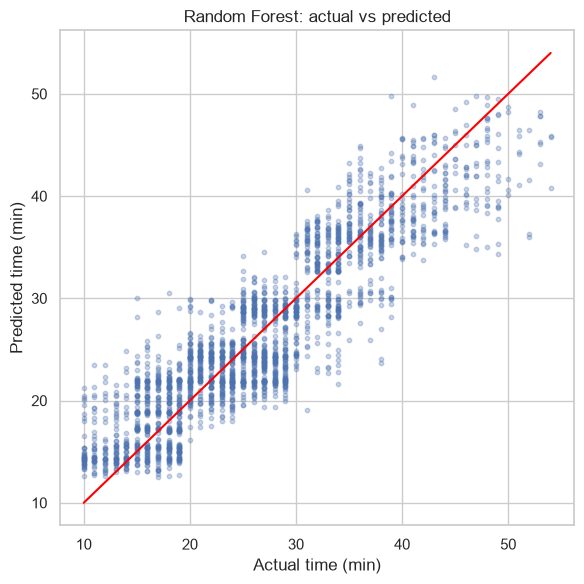

In [15]:
best = rf.best_estimator_
pred = best.predict(X_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.3, s=10)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red')
plt.xlabel('Actual time (min)'); plt.ylabel('Predicted time (min)')
plt.title('Random Forest: actual vs predicted')
plt.tight_layout(); plt.savefig(FIG + '16_actual_vs_predicted.png', dpi=120); plt.show()

**7.2 Residuals.** Residual = actual − predicted. The errors should look random and centred on 0.
A clear pattern or a lopsided shape would mean the model is missing something systematic.

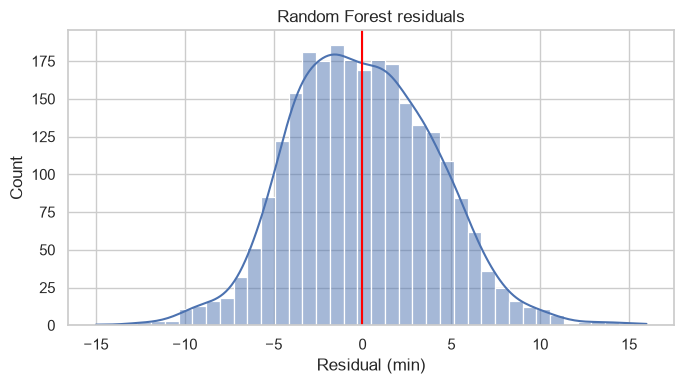

Mean residual: 0.04 min


In [16]:
residuals = y_test - pred
plt.figure(figsize=(7, 4))
sns.histplot(residuals, bins=40, kde=True)
plt.axvline(0, color='red')
plt.xlabel('Residual (min)'); plt.title('Random Forest residuals')
plt.tight_layout(); plt.savefig(FIG + '17_residuals.png', dpi=120); plt.show()
print('Mean residual:', round(residuals.mean(), 2), 'min')

**7.3 Random Forest feature importance.** Shows which inputs the forest relied on most when splitting.
This answers the project question: *which factors matter most for delivery time?*
We get the column names (after one-hot encoding) from the fitted preprocessor.

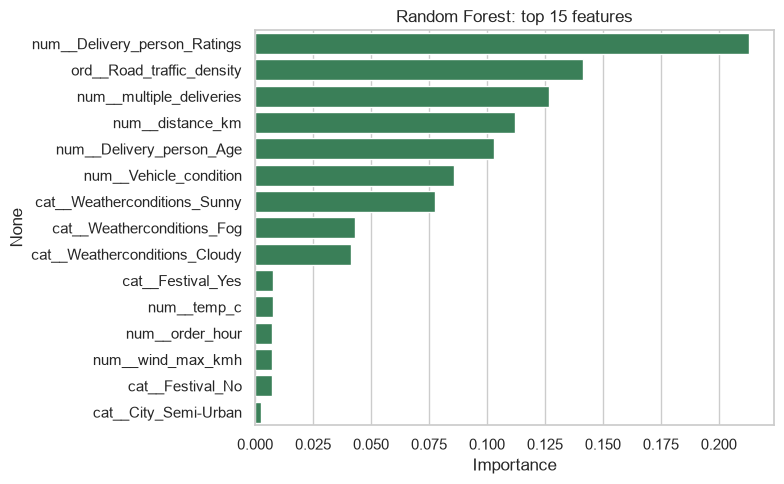

In [17]:
names = best.named_steps['prep'].get_feature_names_out()
importance = pd.Series(best.named_steps['model'].feature_importances_, index=names)
top15 = importance.sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 5))
sns.barplot(x=top15.values, y=top15.index, color='seagreen')
plt.xlabel('Importance'); plt.title('Random Forest: top 15 features')
plt.tight_layout(); plt.savefig(FIG + '18_rf_importance.png', dpi=120); plt.show()

**7.4 Lasso coefficients.** The linear view of the same question. Because numeric features are scaled,
each coefficient is "minutes per one standard deviation" (or per category, for one-hot columns):
positive = adds minutes, negative = saves minutes, zero = Lasso dropped it.

Dropped by Lasso (coef = 0): ['cat__Weatherconditions_Windy', 'cat__City_Metropolitan', 'cat__Type_of_vehicle_bicycle']


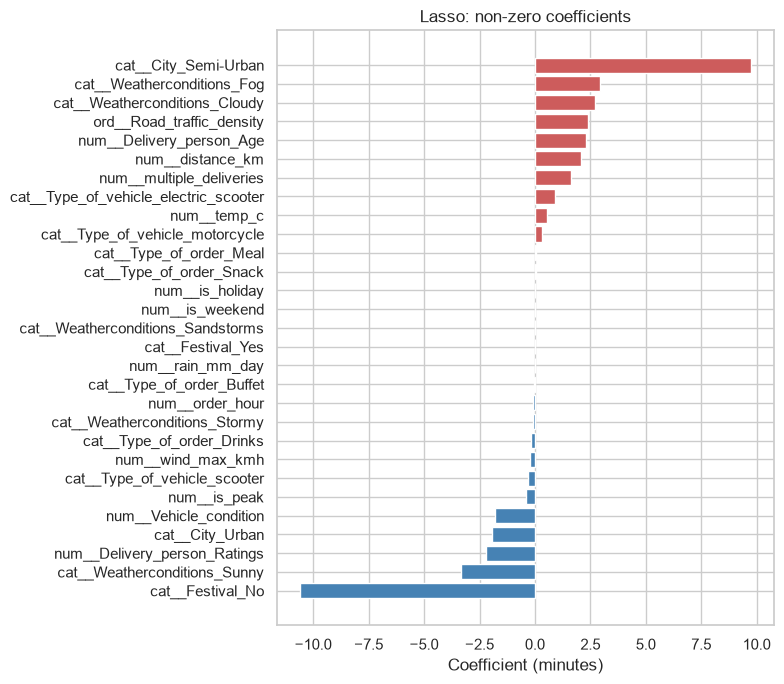

In [18]:
lasso_best = lasso.best_estimator_
coefs = pd.Series(lasso_best.named_steps['model'].coef_,
                  index=lasso_best.named_steps['prep'].get_feature_names_out())
print('Dropped by Lasso (coef = 0):', list(coefs[coefs == 0].index))
nonzero = coefs[coefs != 0].sort_values()
plt.figure(figsize=(8, 7))
plt.barh(nonzero.index, nonzero.values, color=['indianred' if v > 0 else 'steelblue' for v in nonzero])
plt.xlabel('Coefficient (minutes)'); plt.title('Lasso: non-zero coefficients')
plt.tight_layout(); plt.savefig(FIG + '19_lasso_coefficients.png', dpi=120); plt.show()

## 8 · Does real weather help?

**8.1 Random Forest without Open-Meteo columns.** The EDA showed temperature and rain barely correlate with
delivery time. We test this directly: retrain the best Random Forest (same settings) without
`temp_c`, `rain_mm_day` and `wind_max_kmh`, and compare R² with vs without them.

In [19]:
meteo = ['temp_c', 'rain_mm_day', 'wind_max_kmh']
numeric_no_meteo = [c for c in numeric_cols if c not in meteo]
prep_no_meteo = ColumnTransformer([
    ('num', StandardScaler(), numeric_no_meteo),
    ('ord', OrdinalEncoder(categories=traffic_order), ordinal_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), nominal_cols)])
rf_params = {k.replace('model__', ''): v for k, v in rf.best_params_.items()}
rf_no_meteo = Pipeline([('prep', prep_no_meteo),
                        ('model', RandomForestRegressor(random_state=42, n_jobs=-1, **rf_params))])
rf_no_meteo.fit(X_train.drop(columns=meteo), y_train)
r2_without = r2_score(y_test, rf_no_meteo.predict(X_test.drop(columns=meteo)))
print(f'R² with weather:    {rf_scores["R2"]:.3f}')
print(f'R² without weather: {r2_without:.3f}')

R² with weather:    0.813
R² without weather: 0.814


## 9 · Conclusion

| Model | R² | MAE (min) | RMSE (min) | 5-fold CV R² |
|---|---|---|---|---|
| **Random Forest** (max_depth=10, 200 trees) | **0.813** | **3.25** | **4.04** | 0.806 ± 0.009 |
| Ridge (α=1) | 0.576 | 4.87 | 6.07 | 0.578 ± 0.008 |
| Linear Regression | 0.576 | 4.87 | 6.07 | 0.578 ± 0.008 |
| Lasso (α=0.001) | 0.576 | 4.87 | 6.07 | 0.578 ± 0.008 |

- **Winner: Random Forest.** It explains ~81% of the variation in delivery time and is off by ~3.2 minutes on average,
  versus ~4.9 minutes for the linear models. Cross-validation gives almost the same score (0.806 ± 0.009), so the result is stable, not a lucky split.
- **Why it won:** the EDA showed step-like effects and interactions (e.g. Cloudy/Fog + Jam ≈ 36.7 min while Sunny stays ≈ 22 min at every
  traffic level; 2–3 multiple deliveries jump sharply). Straight lines can't bend to fit these; trees split on them directly.
  Ridge and Lasso match plain Linear Regression because with ~10k rows and 30 columns there is little overfitting for the penalty to fix.
- **Top 5 factors (RF importance):** rider rating, traffic density, multiple deliveries, distance, rider age.
  This matches the EDA (traffic, multiple deliveries and the distance/rating/age correlations all stood out).
  Vehicle condition and the weather label (Sunny vs Fog/Cloudy) come next.
  **Festival** ranks low despite the biggest average jump (+20 min) in the EDA. Only 250 of 12,645 orders (2%) are during a festival,
  and tree importance rewards features that help on many orders.
- **Did Open-Meteo weather help? No.** R² is 0.813 with temperature/rain/wind and 0.814 without, which confirms the EDA (|r| < 0.03).
  Lasso also kept those coefficients near zero. The dataset's own weather *label* carries the signal; measured weather does not.
- **Limitations:** only 4 cities; a ~5-week window (Feb–Apr 2022), so no monsoon or seasonal effects; the dataset's coordinates are
  synthetic, so `distance_km` is approximate; rare categories (Semi-Urban 41 orders, bicycle 20) are too small to learn reliably.